# 02 — Your first A-scan

Companion notebook to *Your first A-scan* (`docs/substack/02-your-first-a-scan.md`).
pic0rick python library **v0.1.8**. Offline by default: uses a 5 MHz contact probe on a
10 mm 1018-steel block from `docs/data/calibration_block_5steps_1018steel.h5`.

In [1]:
# --- common setup: find the repo, import the pic0rick library, pin the version
import sys, pathlib
import numpy as np
import matplotlib.pyplot as plt

REPO = next(p for p in pathlib.Path.cwd().resolve().parents if (p / "python" / "pic0rick").is_dir())
sys.path.insert(0, str(REPO / "python"))
import pic0rick

WRITTEN_FOR = "0.1.8"   # pic0rick python library version this notebook was written against
print("pic0rick python library:", pic0rick.__version__, "(notebook written for", WRITTEN_FOR + ")")
if pic0rick.__version__ != WRITTEN_FOR:
    print("WARNING: library version differs -- the API may have moved, check python/Readme.md")

FIG = pathlib.Path("../images"); FIG.mkdir(exist_ok=True)
DATA = REPO / "docs" / "data"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.grid": True, "grid.alpha": 0.3})

LIVE = False   # set True with a pic0rick (firmware -DDSP build, v0.1.11+) plugged in

pic0rick python library: 0.1.8 (notebook written for 0.1.8)


## 1. Acquire (or load) one trace

`UltrasonicAcquisition.from_probe()` sets the gain, configures + arms the pulser, reads a raw
frame and normalises it to `(code − 512) / 512`. It caches into HDF5, so re-running with the same
parameters loads from disk instead of firing again.

In [2]:
from pic0rick.ndt_acquisition import UltrasonicAcquisition, load_h5

H5 = DATA / "calibration_block_5steps_1018steel.h5"
if LIVE:
    a = UltrasonicAcquisition.from_probe(Fech=60e6, gain=350, pon=95, poff=95, damp=6000,
                                         piezo_id="my 5MHz probe", target="steel ~10mm",
                                         h5_path="my_first_ascan.h5")
else:
    acqs = load_h5(str(H5))
    a = next(x for x in acqs if x.gain == 350 and x.pon == 95 and "10.0mm" in x.target)
a.piezo_central_freq, a.piezo_bandwidth = 5e6, 2e6
print(a.label())
print("gain", a.gain, "| pulse", a.pulse, "| samples", a.signal.size)

Calibration 1018 steel block, ~10.0mm  |  piezo=Pink 5MHz  |  gain=350.0 (DAC)  |  pon=95, poff=95, damp=6000  |  Fech=60.00 MHz
gain 350.0 | pulse {'pon': 95, 'poff': 95, 'damp': 6000} | samples 8000


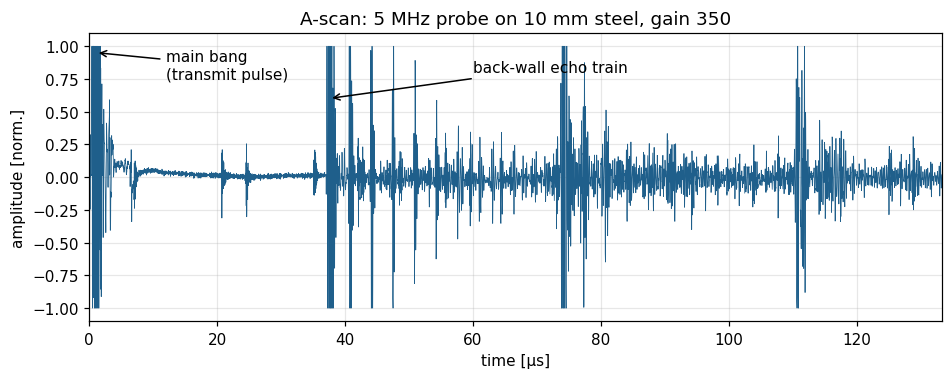

In [3]:
t_us = a.t * 1e6
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(t_us, a.signal, lw=0.5, color="#1f5f8b")
ax.annotate("main bang\n(transmit pulse)", xy=(1, 0.95), xytext=(12, 0.75), arrowprops=dict(arrowstyle="->"))
ax.annotate("back-wall echo train", xy=(37.5, 0.6), xytext=(60, 0.8), arrowprops=dict(arrowstyle="->"))
ax.set(xlabel="time [µs]", ylabel="amplitude [norm.]", xlim=(0, t_us[-1]),
       title="A-scan: 5 MHz probe on 10 mm steel, gain 350")
fig.savefig(FIG / "02-ascan-raw.png")

## 2. What frequency are we looking at?

The spectrum of the echo window should sit around the transducer's 5 MHz.

spectral peak: 5.05 MHz


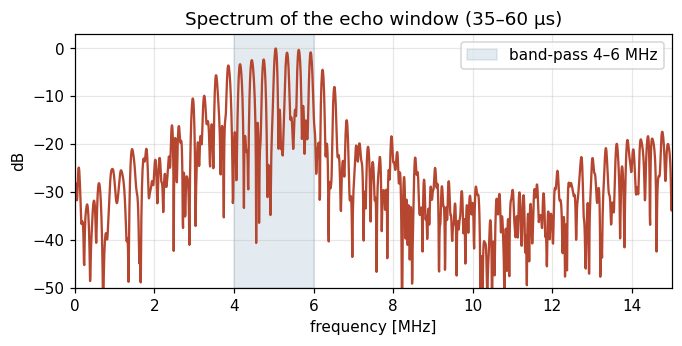

In [4]:
w = (t_us > 35) & (t_us < 60)
seg = a.signal[w] - a.signal[w].mean()
spec = np.abs(np.fft.rfft(seg * np.hanning(seg.size), n=8192))
f_mhz = np.fft.rfftfreq(8192, 1 / a.Fech) / 1e6
f_peak = f_mhz[np.argmax(spec)]
print("spectral peak: %.2f MHz" % f_peak)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(f_mhz, 20 * np.log10(spec / spec.max() + 1e-9), color="#b5462f")
ax.axvspan(4, 6, color="#1f5f8b", alpha=0.12, label="band-pass 4–6 MHz")
ax.set(xlim=(0, 15), ylim=(-50, 3), xlabel="frequency [MHz]", ylabel="dB",
       title="Spectrum of the echo window (35–60 µs)")
ax.legend()
fig.savefig(FIG / "02-spectrum.png")

## 3. Filter and take the envelope

A zero-phase Butterworth band-pass (`a.signal_filtered`) removes the out-of-band junk, and the
magnitude of the analytic signal (Hilbert transform) gives the envelope — the same quantity the
RP2350 DSP build computes on-board with `read_fft`.

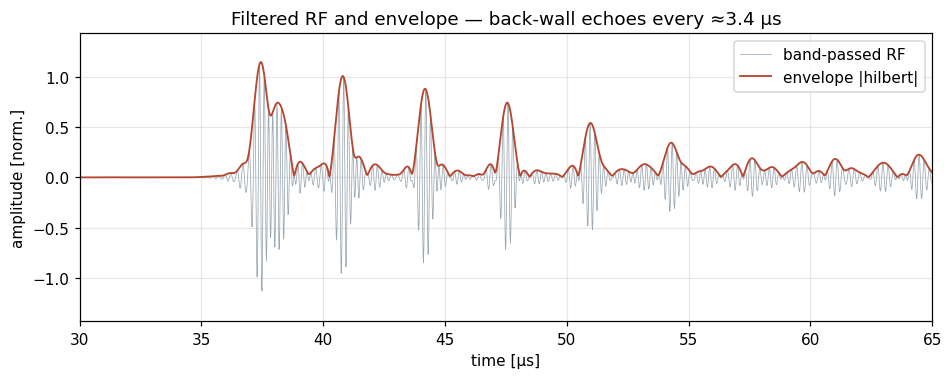

In [5]:
from scipy.signal import hilbert

filt = a.signal_filtered
env = np.abs(hilbert(filt))
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(t_us, filt, lw=0.5, color="#9aa7b1", label="band-passed RF")
ax.plot(t_us, env, lw=1.2, color="#b5462f", label="envelope |hilbert|")
ax.set(xlim=(30, 65), xlabel="time [µs]", ylabel="amplitude [norm.]",
       title="Filtered RF and envelope — back-wall echoes every ≈3.4 µs")
ax.legend(loc="upper right")
fig.savefig(FIG / "02-envelope.png")

## 4. The on-board envelope (DSP build)

The RP2350 can do this itself: `read_fft` returns a 4096-sample float envelope, computed by
CMSIS-DSP on the Pico. Below is one such frame recorded on the bench.

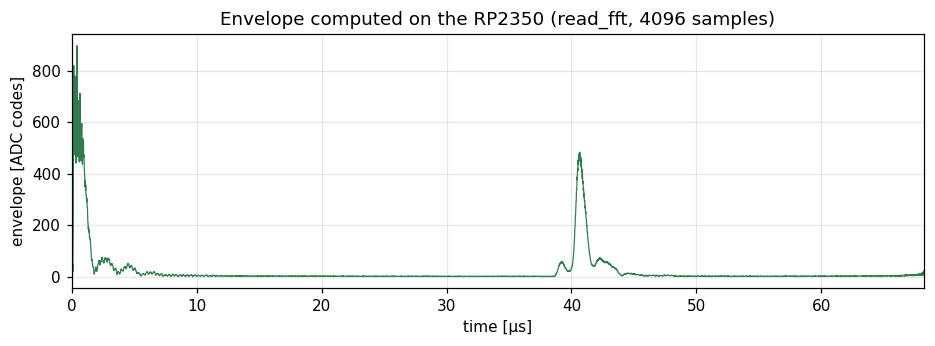

In [6]:
if LIVE:
    from pic0rick.device import Pic0rick
    probe = Pic0rick(verbose=False)
    probe.arm_pulser()
    onboard = probe.read_fft().samples()
    probe.disarm_pulser()
else:
    onboard = np.load(DATA / "dsp_captures" / "envelope" / "envelope.npy")
t2 = np.arange(onboard.size) / 60e6 * 1e6
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t2, onboard, color="#2f7d4f", lw=0.8)
ax.set(xlabel="time [µs]", ylabel="envelope [ADC codes]", xlim=(0, t2[-1]),
       title="Envelope computed on the RP2350 (read_fft, 4096 samples)")
fig.savefig(FIG / "02-onboard-envelope.png")